# Практическая работа №5
## Первичный анализ данных Titanic

**Вариант:** уровень B

В работе выполняется первичный анализ набора данных Titanic:
- изучение структуры данных;
- проверка типов столбцов;
- поиск пропущенных значений;
- получение базовых статистик;
- построение графиков;
- формулирование наблюдений о данных.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("../data/titanic.csv")

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [5]:
print("Размер таблицы:")
print(df.shape)

Размер таблицы:
(418, 12)


In [7]:
print("Названия столбцов:")
print(df.columns.tolist())

Названия столбцов:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [8]:
print("Типы столбцов:")
print(df.dtypes)

Типы столбцов:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


In [9]:
print("Количество пропусков:")
print(df.isnull().sum())

Количество пропусков:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64


## Базовые статистики

Для числовых признаков используем метод `describe()`, который позволяет получить основные статистические показатели: количество значений, среднее значение, стандартное отклонение, минимум, квартили и максимум.

In [10]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,418.000000,418.000000,418.000000,332.000000,418.000000,418.000000,417.000000
mean,1100.500000,0.363636,2.265550,30.272590,0.447368,0.392344,35.627188
std,120.810458,0.481622,0.841838,14.181209,0.896760,0.981429,55.907576
min,892.000000,0.000000,1.000000,0.170000,0.000000,0.000000,0.000000
25%,996.250000,0.000000,1.000000,21.000000,0.000000,0.000000,7.895800
50%,1100.500000,0.000000,3.000000,27.000000,0.000000,0.000000,14.454200
75%,1204.750000,1.000000,3.000000,39.000000,1.000000,0.000000,31.500000
max,1309.000000,1.000000,3.000000,76.000000,8.000000,9.000000,512.329200


## Распределение возраста пассажиров

Рассмотрим распределение возраста пассажиров с помощью гистограммы.

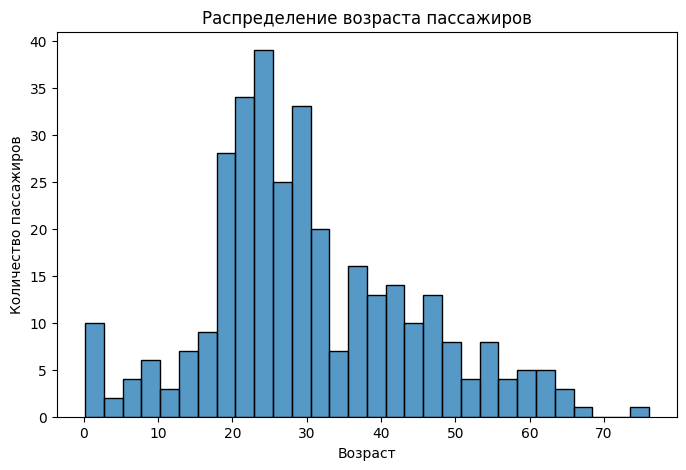

In [11]:
plt.figure(figsize=(8, 5))

sns.histplot(df["Age"].dropna(), bins=30)

plt.title("Распределение возраста пассажиров")
plt.xlabel("Возраст")
plt.ylabel("Количество пассажиров")

plt.show()

## Соотношение мужчин и женщин

Рассмотрим количество пассажиров разных полов.

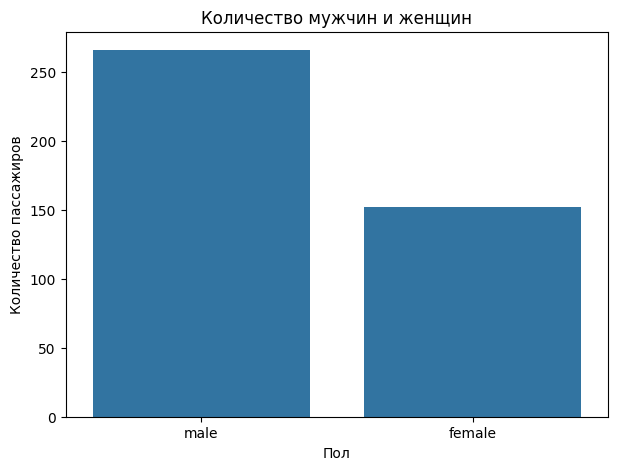

In [12]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Sex")

plt.title("Количество мужчин и женщин")
plt.xlabel("Пол")
plt.ylabel("Количество пассажиров")

plt.show()

## Выживаемость в зависимости от пола

Рассмотрим количество выживших и погибших пассажиров в зависимости от пола.

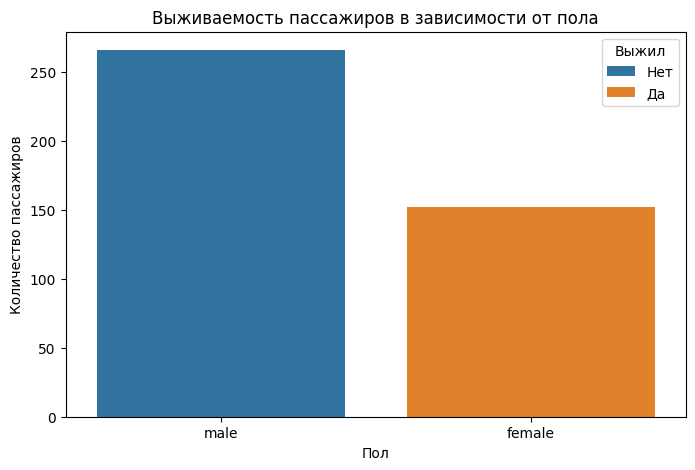

In [13]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Sex", hue="Survived")

plt.title("Выживаемость пассажиров в зависимости от пола")
plt.xlabel("Пол")
plt.ylabel("Количество пассажиров")

plt.legend(title="Выжил", labels=["Нет", "Да"])

plt.show()

## Наблюдения

1. В данных присутствуют пропуски, причём они распределены неравномерно: особенно много пропущенных значений находится в столбце `Cabin`, тогда как в большинстве остальных столбцов пропусков значительно меньше или они отсутствуют.

2. Распределение возраста неоднородное: пассажиры представлены в широком диапазоне возрастов, но количество пассажиров в разных возрастных группах заметно отличается.

3. Категория пола распределена неравномерно. График также показывает различия в количестве выживших и погибших между мужчинами и женщинами, что указывает на связь между этими категориальными признаками.

## Вывод

В ходе работы был выполнен первичный анализ датасета Titanic. Были изучены размер таблицы, типы данных и пропущенные значения, а также рассчитаны базовые статистики. Для визуального анализа были построены графики распределения возраста и соотношения категорий пола и выживаемости. Анализ позволил выявить особенности распределения данных и наличие пропусков, которые необходимо учитывать при дальнейшей обработке датасета.